# Bonus — Clasificación de larvas con MLMI-2024

Este notebook desarrolla un modelo experimental independiente para imágenes microscópicas de larvas. No modifica el clasificador de mosquitos adultos de VectorIA.

Primero se verificará la estructura y las etiquetas reales del dataset; después se definirán las clases, la división de datos y el modelo.

In [1]:
from pathlib import Path
from collections import Counter

## Liberías

In [2]:
import importlib.util

paquetes = [
    "numpy",
    "pandas",
    "matplotlib",
    "PIL",
    "tensorflow",
    "sklearn",
    "seaborn"
]

for paquete in paquetes:
    encontrado = (
        importlib.util.find_spec(paquete)
        is not None
    )

    print(
        f"{paquete:12}: "
        f"{'OK' if encontrado else 'FALTA'}"
    )

numpy       : OK
pandas      : OK
matplotlib  : OK
PIL         : OK
tensorflow  : OK
sklearn     : OK
seaborn     : OK


In [3]:
import sys

print("Python:")
print(sys.executable)

print("\nVersión:")
print(sys.version)

Python:
C:\VectorAI\VectorIA\.venv311\Scripts\python.exe

Versión:
3.11.0 (main, Oct 24 2022, 18:26:48) [MSC v.1933 64 bit (AMD64)]


In [4]:
import sys
import matplotlib

print("PYTHON:")
print(sys.executable)

print("\nMATPLOTLIB OBJETO:")
print(matplotlib)

print("\nMATPLOTLIB FILE:")
print(
    getattr(
        matplotlib,
        "__file__",
        "NO TIENE __file__"
    )
)

print("\nMATPLOTLIB PATH:")
print(
    getattr(
        matplotlib,
        "__path__",
        "NO TIENE __path__"
    )
)

print("\nPRIMERAS RUTAS PYTHON:")
for ruta in sys.path[:10]:
    print(ruta)

PYTHON:
C:\VectorAI\VectorIA\.venv311\Scripts\python.exe

MATPLOTLIB OBJETO:
<module 'matplotlib' from 'C:\\VectorAI\\VectorIA\\.venv311\\Lib\\site-packages\\matplotlib\\__init__.py'>

MATPLOTLIB FILE:
C:\VectorAI\VectorIA\.venv311\Lib\site-packages\matplotlib\__init__.py

MATPLOTLIB PATH:
['C:\\VectorAI\\VectorIA\\.venv311\\Lib\\site-packages\\matplotlib']

PRIMERAS RUTAS PYTHON:
C:\Program Files\JetBrains\PyCharm 2026.2.4\plugins\python-ce\helpers
C:\VectorAI\VectorIA

C:\VectorAI\VectorIA\.venv311\Lib\site-packages
C:\VectorAI\VectorIA\src
C:\Program Files\JetBrains\PyCharm 2026.2.4\plugins\python-ce\helpers
C:\Users\maortiz\AppData\Local\Programs\Python\Python311\python311.zip
C:\Users\maortiz\AppData\Local\Programs\Python\Python311\DLLs
C:\Users\maortiz\AppData\Local\Programs\Python\Python311\Lib
C:\Users\maortiz\AppData\Local\Programs\Python\Python311


In [1]:
import seaborn

print("Seaborn:")
print(seaborn.__version__)
print(seaborn.__file__)

Seaborn:
0.13.2
C:\VectorAI\VectorIA\.venv311\Lib\site-packages\seaborn\__init__.py


In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


PROYECTO = Path(
    r"C:\VectorAI\VectorIA"
)

RUTA_MLMI = (
    PROYECTO
    / "data"
    / "raw"
    / "MLMI-2024 (Mosquito Larvae Microscopic Images)"
)

EXTENSIONES_IMAGEN = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}

SEED = 42

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Dataset:", RUTA_MLMI)
print("¿Existe?:", RUTA_MLMI.is_dir())

assert RUTA_MLMI.is_dir(), (
    f"No se encontró MLMI-2024: {RUTA_MLMI}"
)

print(
    "\n✅ Entorno del bonus MLMI-2024 preparado."
)

TensorFlow: 2.21.0
Dataset: C:\VectorAI\VectorIA\data\raw\MLMI-2024 (Mosquito Larvae Microscopic Images)
¿Existe?: True

✅ Entorno del bonus MLMI-2024 preparado.


## Inspeccionar la estructura real

In [2]:
print("=" * 60)
print("ESTRUCTURA MLMI-2024")
print("=" * 60)

print("\nContenido principal:\n")

for elemento in sorted(
    RUTA_MLMI.iterdir(),
    key=lambda x: x.name.lower()
):

    tipo = (
        "CARPETA"
        if elemento.is_dir()
        else "ARCHIVO"
    )

    print(
        f"[{tipo}] {elemento.name}"
    )


print(
    "\nCarpetas que contienen imágenes:\n"
)

for carpeta in sorted(
    RUTA_MLMI.rglob("*"),
    key=lambda x: str(x).lower()
):

    if not carpeta.is_dir():
        continue

    imagenes_directas = [
        archivo
        for archivo in carpeta.iterdir()
        if archivo.is_file()
        and archivo.suffix.lower()
        in EXTENSIONES_IMAGEN
    ]

    if imagenes_directas:

        print(
            f"{carpeta.relative_to(RUTA_MLMI)}"
            f" -> "
            f"{len(imagenes_directas)} imágenes"
        )

ESTRUCTURA MLMI-2024

Contenido principal:

[CARPETA] MLMI-2024 (Mosquito Larvae Microscopic Images)

Carpetas que contienen imágenes:

MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Aedes aegypti\abdomen -> 100 imágenes
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Aedes aegypti\full body -> 100 imágenes
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Aedes aegypti\head -> 100 imágenes
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Aedes aegypti\siphon -> 100 imágenes
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Culex quinquefasciatus\abdomen -> 100 imágenes
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Culex quinquefasciatus\full body -> 100 imágenes
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Culex quinquefasciatus\head -> 100 imágenes
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Culex quinquefasciatus\siphon -> 100 imágenes


## Inventariar imágenes y localizar etiquetas

In [3]:
imagenes_mlmi = sorted(
    [
        archivo
        for archivo in RUTA_MLMI.rglob("*")
        if archivo.is_file()
        and archivo.suffix.lower()
        in EXTENSIONES_IMAGEN
    ],
    key=lambda x: str(x).lower()
)


archivos_etiquetas = sorted(
    [
        archivo
        for archivo in RUTA_MLMI.rglob("*")
        if archivo.is_file()
        and archivo.suffix.lower()
        in {
            ".csv",
            ".json",
            ".xlsx",
            ".xls",
            ".txt"
        }
    ],
    key=lambda x: str(x).lower()
)


print("=" * 60)
print("INVENTARIO INICIAL")
print("=" * 60)

print(
    "Total de imágenes encontradas:",
    len(imagenes_mlmi)
)


print(
    "\nPosibles archivos de etiquetas:"
)

if archivos_etiquetas:

    for archivo in archivos_etiquetas:

        print(
            "-",
            archivo.relative_to(
                RUTA_MLMI
            )
        )

else:

    print(
        "No se encontraron archivos "
        "CSV/JSON/XLSX/XLS/TXT."
    )


print(
    "\nPrimeras 20 imágenes:"
)

for archivo in imagenes_mlmi[:20]:

    print(
        archivo.relative_to(
            RUTA_MLMI
        )
    )

INVENTARIO INICIAL
Total de imágenes encontradas: 800

Posibles archivos de etiquetas:
No se encontraron archivos CSV/JSON/XLSX/XLS/TXT.

Primeras 20 imágenes:
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Aedes aegypti\abdomen\20231211_131111.jpg
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Aedes aegypti\abdomen\20231211_131132.jpg
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Aedes aegypti\abdomen\20231211_131207.jpg
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Aedes aegypti\abdomen\20231211_131248.jpg
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Aedes aegypti\abdomen\20231211_131334.jpg
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Aedes aegypti\abdomen\20231211_131401.jpg
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Aedes aegypti\abdomen\20231211_131554.jpg
MLMI-2024 (Mosquito Larvae Microscopic Images)\MLMI-2024\Aedes aegypti\abdomen\20231211_131644.jpg
MLMI-2024 (Mosquito Larvae Microscopic Images)\M

## Analizar carpetas padre

In [4]:
conteo_carpetas_padre = Counter(
    str(
        archivo.parent.relative_to(
            RUTA_MLMI
        )
    )
    for archivo in imagenes_mlmi
)


df_carpetas_mlmi = pd.DataFrame(
    [
        {
            "carpeta": carpeta,
            "imagenes": cantidad
        }
        for carpeta, cantidad
        in conteo_carpetas_padre.items()
    ]
).sort_values(
    "imagenes",
    ascending=False
)


print(
    "Cantidad de carpetas con imágenes:",
    len(df_carpetas_mlmi)
)

display(
    df_carpetas_mlmi
)

Cantidad de carpetas con imágenes: 8


,carpeta,imagenes
0,MLMI-2024 (Mosquito Larvae Microscopic Images)...,100
1,MLMI-2024 (Mosquito Larvae Microscopic Images)...,100
2,MLMI-2024 (Mosquito Larvae Microscopic Images)...,100
3,MLMI-2024 (Mosquito Larvae Microscopic Images)...,100
4,MLMI-2024 (Mosquito Larvae Microscopic Images)...,100
5,MLMI-2024 (Mosquito Larvae Microscopic Images)...,100
6,MLMI-2024 (Mosquito Larvae Microscopic Images)...,100
7,MLMI-2024 (Mosquito Larvae Microscopic Images)...,100


## Definir las dos clases

In [5]:
CLASES_LARVAS = [
    "Aedes aegypti",
    "Culex quinquefasciatus"
]

CLASS_TO_ID_LARVAS = {
    clase: indice
    for indice, clase
    in enumerate(CLASES_LARVAS)
}

ID_TO_CLASS_LARVAS = {
    indice: clase
    for clase, indice
    in CLASS_TO_ID_LARVAS.items()
}

REGIONES_LARVAS = [
    "abdomen",
    "full body",
    "head",
    "siphon"
]

NUM_CLASES_LARVAS = len(
    CLASES_LARVAS
)

print("Clases:")

for clase, class_id in (
    CLASS_TO_ID_LARVAS.items()
):
    print(
        f"{class_id}: {clase}"
    )

print("\nRegiones:")

for region in REGIONES_LARVAS:
    print("-", region)

Clases:
0: Aedes aegypti
1: Culex quinquefasciatus

Regiones:
- abdomen
- full body
- head
- siphon


## Crear el inventario MLMI

In [6]:
registros_mlmi = []

for archivo in imagenes_mlmi:

    ruta_relativa = archivo.relative_to(
        RUTA_MLMI
    )

    partes = [
        parte.lower()
        for parte in ruta_relativa.parts
    ]

    # ==========================================
    # ESPECIE
    # ==========================================

    if "aedes aegypti" in partes:

        class_name = "Aedes aegypti"

    elif "culex quinquefasciatus" in partes:

        class_name = "Culex quinquefasciatus"

    else:

        class_name = None

    # ==========================================
    # REGIÓN ANATÓMICA
    # ==========================================

    body_region = None

    for region in REGIONES_LARVAS:

        if region in partes:

            body_region = region
            break

    if class_name is None:
        continue

    if body_region is None:
        continue

    registros_mlmi.append({
        "filepath": str(
            archivo.resolve()
        ),

        "filename": archivo.name,

        "class_name": class_name,

        "class_id": (
            CLASS_TO_ID_LARVAS[
                class_name
            ]
        ),

        "body_region": body_region
    })


df_mlmi = pd.DataFrame(
    registros_mlmi
)

print("=" * 60)
print("INVENTARIO MLMI")
print("=" * 60)

print(
    "Registros:",
    len(df_mlmi)
)

display(
    df_mlmi.head(10)
)

INVENTARIO MLMI
Registros: 800


,filepath,filename,class_name,class_id,body_region
0,C:\VectorAI\VectorIA\data\raw\MLMI-2024 (Mosqu...,20231211_131111.jpg,Aedes aegypti,0,abdomen
1,C:\VectorAI\VectorIA\data\raw\MLMI-2024 (Mosqu...,20231211_131132.jpg,Aedes aegypti,0,abdomen
2,C:\VectorAI\VectorIA\data\raw\MLMI-2024 (Mosqu...,20231211_131207.jpg,Aedes aegypti,0,abdomen
3,C:\VectorAI\VectorIA\data\raw\MLMI-2024 (Mosqu...,20231211_131248.jpg,Aedes aegypti,0,abdomen
4,C:\VectorAI\VectorIA\data\raw\MLMI-2024 (Mosqu...,20231211_131334.jpg,Aedes aegypti,0,abdomen
5,C:\VectorAI\VectorIA\data\raw\MLMI-2024 (Mosqu...,20231211_131401.jpg,Aedes aegypti,0,abdomen
6,C:\VectorAI\VectorIA\data\raw\MLMI-2024 (Mosqu...,20231211_131554.jpg,Aedes aegypti,0,abdomen
7,C:\VectorAI\VectorIA\data\raw\MLMI-2024 (Mosqu...,20231211_131644.jpg,Aedes aegypti,0,abdomen
8,C:\VectorAI\VectorIA\data\raw\MLMI-2024 (Mosqu...,20231211_131720.jpg,Aedes aegypti,0,abdomen
9,C:\VectorAI\VectorIA\data\raw\MLMI-2024 (Mosqu...,20231211_131744.jpg,Aedes aegypti,0,abdomen


## Validar distribución

In [7]:
print(
    "Distribución por especie:"
)

display(
    df_mlmi[
        "class_name"
    ].value_counts()
)

print(
    "\nDistribución por región:"
)

display(
    df_mlmi[
        "body_region"
    ].value_counts()
)

print(
    "\nEspecie × región:"
)

tabla_mlmi = pd.crosstab(
    df_mlmi["class_name"],
    df_mlmi["body_region"]
)

tabla_mlmi = tabla_mlmi.reindex(
    index=CLASES_LARVAS,
    columns=REGIONES_LARVAS,
    fill_value=0
)

display(
    tabla_mlmi
)

Distribución por especie:


class_name
Aedes aegypti             400
Culex quinquefasciatus    400
Name: count, dtype: int64


Distribución por región:


body_region
abdomen      200
full body    200
head         200
siphon       200
Name: count, dtype: int64


Especie × región:


body_region,abdomen,full body,head,siphon
class_name,,,,
Aedes aegypti,100,100,100,100
Culex quinquefasciatus,100,100,100,100


## validamos automáticamente

In [8]:
assert len(df_mlmi) == 800

assert (
    df_mlmi["class_name"]
    .value_counts()
    .eq(400)
    .all()
)

assert (
    df_mlmi["body_region"]
    .value_counts()
    .eq(200)
    .all()
)

assert (
    tabla_mlmi
    .eq(100)
    .all()
    .all()
)

print(
    "✅ MLMI está perfectamente "
    "balanceado por especie y región."
)

✅ MLMI está perfectamente balanceado por especie y región.


## Analizar dimensiones

In [9]:
dimensiones_mlmi = []

errores_imagen_mlmi = []

for indice, fila in df_mlmi.iterrows():

    ruta = Path(
        fila["filepath"]
    )

    try:

        with Image.open(
            ruta
        ) as imagen:

            ancho, alto = imagen.size
            modo = imagen.mode

        dimensiones_mlmi.append({
            "indice": indice,
            "width": ancho,
            "height": alto,
            "mode": modo
        })

    except Exception as error:

        errores_imagen_mlmi.append({
            "filepath": str(ruta),
            "error": str(error)
        })


df_dim_mlmi = pd.DataFrame(
    dimensiones_mlmi
).set_index(
    "indice"
)

df_mlmi = df_mlmi.join(
    df_dim_mlmi
)

print(
    "Imágenes legibles:",
    len(df_dim_mlmi)
)

print(
    "Errores:",
    len(errores_imagen_mlmi)
)

print(
    "\nResoluciones diferentes:",
    df_mlmi[
        ["width", "height"]
    ]
    .drop_duplicates()
    .shape[0]
)

display(
    df_mlmi[
        [
            "width",
            "height"
        ]
    ]
    .value_counts()
    .head(20)
    .rename("cantidad")
    .reset_index()
)

print(
    "\nModos de color:"
)

display(
    df_mlmi[
        "mode"
    ].value_counts()
)

Imágenes legibles: 800
Errores: 0

Resoluciones diferentes: 2


,width,height,cantidad
0,3456,3456,799
1,3468,3468,1



Modos de color:


mode
RGB    800
Name: count, dtype: int64

In [12]:
import hashlib

## Buscar duplicados exactos

In [13]:
def calcular_sha256_mlmi(
    filepath,
    block_size=1024 * 1024
):

    digest = hashlib.sha256()

    with open(
        filepath,
        "rb"
    ) as archivo:

        while True:

            bloque = archivo.read(
                block_size
            )

            if not bloque:
                break

            digest.update(
                bloque
            )

    return digest.hexdigest()


df_mlmi["sha256"] = (
    df_mlmi[
        "filepath"
    ].map(
        calcular_sha256_mlmi
    )
)

print(
    "Imágenes:",
    len(df_mlmi)
)

print(
    "Hashes únicos:",
    df_mlmi[
        "sha256"
    ].nunique()
)

duplicados_mlmi = (
    df_mlmi[
        df_mlmi.duplicated(
            subset="sha256",
            keep=False
        )
    ]
    .sort_values(
        [
            "sha256",
            "class_name",
            "body_region"
        ]
    )
)

print(
    "Archivos dentro de grupos duplicados:",
    len(duplicados_mlmi)
)

print(
    "Copias adicionales:",
    int(
        df_mlmi.duplicated(
            subset="sha256",
            keep="first"
        ).sum()
    )
)

if not duplicados_mlmi.empty:

    display(
        duplicados_mlmi[
            [
                "class_name",
                "body_region",
                "filename",
                "width",
                "height",
                "sha256"
            ]
        ].head(30)
    )

else:

    print(
        "✅ No hay duplicados exactos."
    )

Imágenes: 800
Hashes únicos: 800
Archivos dentro de grupos duplicados: 0
Copias adicionales: 0
✅ No hay duplicados exactos.


## Analizar los nombres y tiempos de captura

In [14]:
df_mlmi[
    "filename_stem"
] = (
    df_mlmi["filename"]
    .map(
        lambda nombre:
        Path(nombre).stem
    )
)

print(
    "Nombres únicos:",
    df_mlmi[
        "filename_stem"
    ].nunique()
)

conteo_nombres_mlmi = (
    df_mlmi[
        "filename_stem"
    ]
    .value_counts()
)

nombres_repetidos_mlmi = (
    conteo_nombres_mlmi[
        conteo_nombres_mlmi > 1
    ]
)

print(
    "Nombres repetidos:",
    len(
        nombres_repetidos_mlmi
    )
)

if not nombres_repetidos_mlmi.empty:

    display(
        df_mlmi[
            df_mlmi[
                "filename_stem"
            ].isin(
                nombres_repetidos_mlmi.index
            )
        ][
            [
                "class_name",
                "body_region",
                "filename"
            ]
        ]
        .sort_values(
            [
                "filename",
                "class_name",
                "body_region"
            ]
        )
        .head(50)
    )

else:

    print(
        "✅ No hay nombres repetidos "
        "entre carpetas/regiones."
    )

Nombres únicos: 800
Nombres repetidos: 0
✅ No hay nombres repetidos entre carpetas/regiones.


## Revisar resoluciones y modos de color

In [15]:
print("=" * 60)
print("RESUMEN VISUAL MLMI-2024")
print("=" * 60)

print("\nResoluciones más frecuentes:")

display(
    df_mlmi[
        ["width", "height"]
    ]
    .value_counts()
    .head(15)
    .rename("cantidad")
    .reset_index()
)

print("\nModos de color:")

display(
    df_mlmi[
        "mode"
    ].value_counts()
)

print(
    "\nAncho mínimo/máximo:",
    int(df_mlmi["width"].min()),
    "/",
    int(df_mlmi["width"].max())
)

print(
    "Alto mínimo/máximo:",
    int(df_mlmi["height"].min()),
    "/",
    int(df_mlmi["height"].max())
)

RESUMEN VISUAL MLMI-2024

Resoluciones más frecuentes:


,width,height,cantidad
0,3456,3456,799
1,3468,3468,1



Modos de color:


mode
RGB    800
Name: count, dtype: int64


Ancho mínimo/máximo: 3456 / 3468
Alto mínimo/máximo: 3456 / 3468


## Crear estrato especie + región

In [16]:
df_mlmi[
    "stratum"
] = (
    df_mlmi["class_name"]
    + " | "
    + df_mlmi["body_region"]
)

print(
    "Cantidad de estratos:",
    df_mlmi[
        "stratum"
    ].nunique()
)

display(
    df_mlmi[
        "stratum"
    ].value_counts()
    .sort_index()
)

assert (
    df_mlmi[
        "stratum"
    ].nunique()
    == 8
)

assert (
    df_mlmi[
        "stratum"
    ].value_counts()
    .eq(100)
    .all()
)

print(
    "\n✅ Ocho estratos balanceados."
)

Cantidad de estratos: 8


stratum
Aedes aegypti | abdomen               100
Aedes aegypti | full body             100
Aedes aegypti | head                  100
Aedes aegypti | siphon                100
Culex quinquefasciatus | abdomen      100
Culex quinquefasciatus | full body    100
Culex quinquefasciatus | head         100
Culex quinquefasciatus | siphon       100
Name: count, dtype: int64


✅ Ocho estratos balanceados.


## Crear train / validation / test

In [18]:
from sklearn.model_selection import train_test_split

print("✅ train_test_split disponible.")

✅ train_test_split disponible.


In [19]:
df_train_val_mlmi, df_test_mlmi = (
    train_test_split(
        df_mlmi,
        test_size=0.15,
        random_state=SEED,
        stratify=df_mlmi[
            "stratum"
        ]
    )
)

df_train_mlmi, df_val_mlmi = (
    train_test_split(
        df_train_val_mlmi,
        test_size=(0.15 / 0.85),
        random_state=SEED,
        stratify=df_train_val_mlmi[
            "stratum"
        ]
    )
)

df_train_mlmi = (
    df_train_mlmi
    .copy()
    .reset_index(drop=True)
)

df_val_mlmi = (
    df_val_mlmi
    .copy()
    .reset_index(drop=True)
)

df_test_mlmi = (
    df_test_mlmi
    .copy()
    .reset_index(drop=True)
)

print(
    "Train:",
    len(df_train_mlmi)
)

print(
    "Validation:",
    len(df_val_mlmi)
)

print(
    "Test:",
    len(df_test_mlmi)
)

assert (
    len(df_train_mlmi)
    + len(df_val_mlmi)
    + len(df_test_mlmi)
    == 800
)

print(
    "\n✅ División creada."
)

Train: 559
Validation: 121
Test: 120

✅ División creada.


## Verificar balance de las particiones

In [20]:
def mostrar_split_mlmi(
    dataframe,
    nombre
):

    print(
        "\n" + "=" * 60
    )

    print(nombre)

    print("=" * 60)

    print(
        "Imágenes:",
        len(dataframe)
    )

    print(
        "\nPor especie:"
    )

    display(
        dataframe[
            "class_name"
        ]
        .value_counts()
        .reindex(
            CLASES_LARVAS,
            fill_value=0
        )
    )

    print(
        "\nEspecie × región:"
    )

    display(
        pd.crosstab(
            dataframe[
                "class_name"
            ],
            dataframe[
                "body_region"
            ]
        )
        .reindex(
            index=CLASES_LARVAS,
            columns=REGIONES_LARVAS,
            fill_value=0
        )
    )


mostrar_split_mlmi(
    df_train_mlmi,
    "TRAIN"
)

mostrar_split_mlmi(
    df_val_mlmi,
    "VALIDATION"
)

mostrar_split_mlmi(
    df_test_mlmi,
    "TEST"
)


TRAIN
Imágenes: 559

Por especie:


class_name
Aedes aegypti             280
Culex quinquefasciatus    279
Name: count, dtype: int64


Especie × región:


body_region,abdomen,full body,head,siphon
class_name,,,,
Aedes aegypti,70,70,70,70
Culex quinquefasciatus,70,70,69,70



VALIDATION
Imágenes: 121

Por especie:


class_name
Aedes aegypti             60
Culex quinquefasciatus    61
Name: count, dtype: int64

... (2 outputs left out)


TEST
Imágenes: 120

Por especie:


class_name
Aedes aegypti             60
Culex quinquefasciatus    60
Name: count, dtype: int64


Especie × región:


body_region,abdomen,full body,head,siphon
class_name,,,,
Aedes aegypti,15,15,15,15
Culex quinquefasciatus,15,15,15,15


## Verificar cero leakage por SHA-256

In [21]:
hashes_train = set(
    df_train_mlmi[
        "sha256"
    ]
)

hashes_val = set(
    df_val_mlmi[
        "sha256"
    ]
)

hashes_test = set(
    df_test_mlmi[
        "sha256"
    ]
)

print(
    "Train / Validation:",
    len(
        hashes_train
        & hashes_val
    )
)

print(
    "Train / Test:",
    len(
        hashes_train
        & hashes_test
    )
)

print(
    "Validation / Test:",
    len(
        hashes_val
        & hashes_test
    )
)

assert not (
    hashes_train
    & hashes_val
)

assert not (
    hashes_train
    & hashes_test
)

assert not (
    hashes_val
    & hashes_test
)

print(
    "\n✅ No existen hashes "
    "compartidos entre particiones."
)

Train / Validation: 0
Train / Test: 0
Validation / Test: 0

✅ No existen hashes compartidos entre particiones.


## Asignar columna split

In [22]:
df_train_mlmi[
    "split"
] = "train"

df_val_mlmi[
    "split"
] = "validation"

df_test_mlmi[
    "split"
] = "test"


df_splits_mlmi = pd.concat(
    [
        df_train_mlmi,
        df_val_mlmi,
        df_test_mlmi
    ],
    ignore_index=True
)


print(
    "Registros:",
    len(df_splits_mlmi)
)

display(
    pd.crosstab(
        df_splits_mlmi[
            "split"
        ],
        df_splits_mlmi[
            "class_name"
        ]
    )
    .reindex(
        index=[
            "train",
            "validation",
            "test"
        ],
        columns=CLASES_LARVAS,
        fill_value=0
    )
)

Registros: 800


class_name,Aedes aegypti,Culex quinquefasciatus
split,,
train,280,279
validation,60,61
test,60,60


## Guardar checkpoint del bonus

In [25]:
from pathlib import Path

PROYECTO = Path(
    r"C:\VectorAI\VectorIA"
)

PROCESSED_MLMI = (
    PROYECTO
    / "data"
    / "processed"
    / "mlmi"
)

MODELS = (
    PROYECTO
    / "models"
)

PROCESSED_MLMI.mkdir(
    parents=True,
    exist_ok=True
)

MODELS.mkdir(
    parents=True,
    exist_ok=True
)

print("Proyecto:")
print(PROYECTO)

print("\nProcesados MLMI:")
print(PROCESSED_MLMI)

print("\nModelos:")
print(MODELS)

print(
    "\nPROCESSED_MLMI existe:",
    PROCESSED_MLMI.is_dir()
)

print(
    "MODELS existe:",
    MODELS.is_dir()
)

print(
    "\n✅ Rutas MLMI recuperadas."
)

Proyecto:
C:\VectorAI\VectorIA

Procesados MLMI:
C:\VectorAI\VectorIA\data\processed\mlmi

Modelos:
C:\VectorAI\VectorIA\models

PROCESSED_MLMI existe: True
MODELS existe: True

✅ Rutas MLMI recuperadas.


## guardado de Splits

In [26]:
RUTA_SPLITS_MLMI = (
    PROCESSED_MLMI
    / "mlmi_splits.csv"
)

df_splits_mlmi.to_csv(
    RUTA_SPLITS_MLMI,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Splits guardados:"
)

print(
    RUTA_SPLITS_MLMI
)

print(
    "¿Existe?:",
    RUTA_SPLITS_MLMI.is_file()
)

print(
    "Registros:",
    len(df_splits_mlmi)
)

Splits guardados:
C:\VectorAI\VectorIA\data\processed\mlmi\mlmi_splits.csv
¿Existe?: True
Registros: 800


## Visualizar especie × región

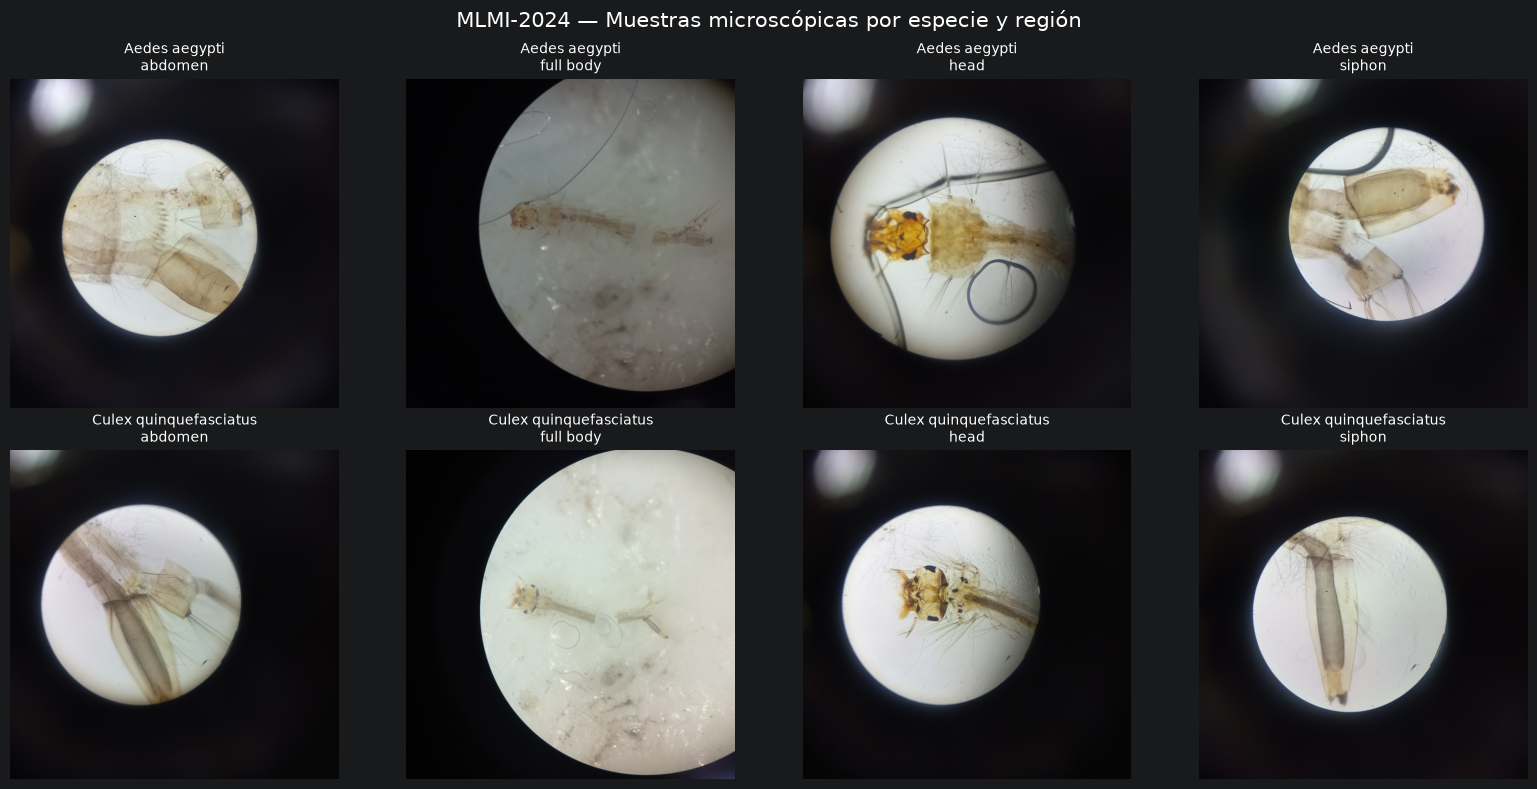

In [27]:
fig, axes = plt.subplots(
    2,
    4,
    figsize=(16, 8)
)

for fila_idx, clase in enumerate(
    CLASES_LARVAS
):

    for columna_idx, region in enumerate(
        REGIONES_LARVAS
    ):

        candidatos = df_train_mlmi[
            (
                df_train_mlmi["class_name"]
                == clase
            )
            &
            (
                df_train_mlmi["body_region"]
                == region
            )
        ]

        fila = candidatos.sample(
            n=1,
            random_state=SEED
        ).iloc[0]

        ruta = Path(
            fila["filepath"]
        )

        with Image.open(
            ruta
        ) as imagen:

            imagen = imagen.convert(
                "RGB"
            )

            axes[
                fila_idx,
                columna_idx
            ].imshow(
                imagen
            )

        axes[
            fila_idx,
            columna_idx
        ].set_title(
            f"{clase}\n{region}",
            fontsize=10
        )

        axes[
            fila_idx,
            columna_idx
        ].axis(
            "off"
        )


plt.suptitle(
    "MLMI-2024 — Muestras microscópicas por especie y región",
    fontsize=15
)

plt.tight_layout()

plt.show()

## Configuración de imágenes

In [28]:
IMG_HEIGHT_MLMI = 192
IMG_WIDTH_MLMI = 192

IMG_SIZE_MLMI = (
    IMG_HEIGHT_MLMI,
    IMG_WIDTH_MLMI
)

BATCH_SIZE_MLMI = 16

print(
    "Tamaño de entrada:",
    IMG_SIZE_MLMI
)

print(
    "Batch size:",
    BATCH_SIZE_MLMI
)

print(
    "Clases:",
    CLASS_TO_ID_LARVAS
)

Tamaño de entrada: (192, 192)
Batch size: 16
Clases: {'Aedes aegypti': 0, 'Culex quinquefasciatus': 1}


## Función de preprocesamiento

In [29]:
def preparar_imagen_mlmi(
    filepath
):

    filepath = Path(
        filepath
    )

    if not filepath.is_file():

        raise FileNotFoundError(
            f"No existe: {filepath}"
        )

    with Image.open(
        filepath
    ) as imagen:

        imagen = imagen.convert(
            "RGB"
        )

        matriz = np.asarray(
            imagen,
            dtype=np.uint8
        )

    tensor = tf.convert_to_tensor(
        matriz,
        dtype=tf.uint8
    )

    tensor = tf.image.resize_with_pad(
        tensor,
        target_height=IMG_HEIGHT_MLMI,
        target_width=IMG_WIDTH_MLMI,
        method="bilinear"
    )

    tensor = tf.cast(
        tensor,
        tf.float32
    )

    return tensor

## Probar el preprocesamiento en las 8 combinaciones

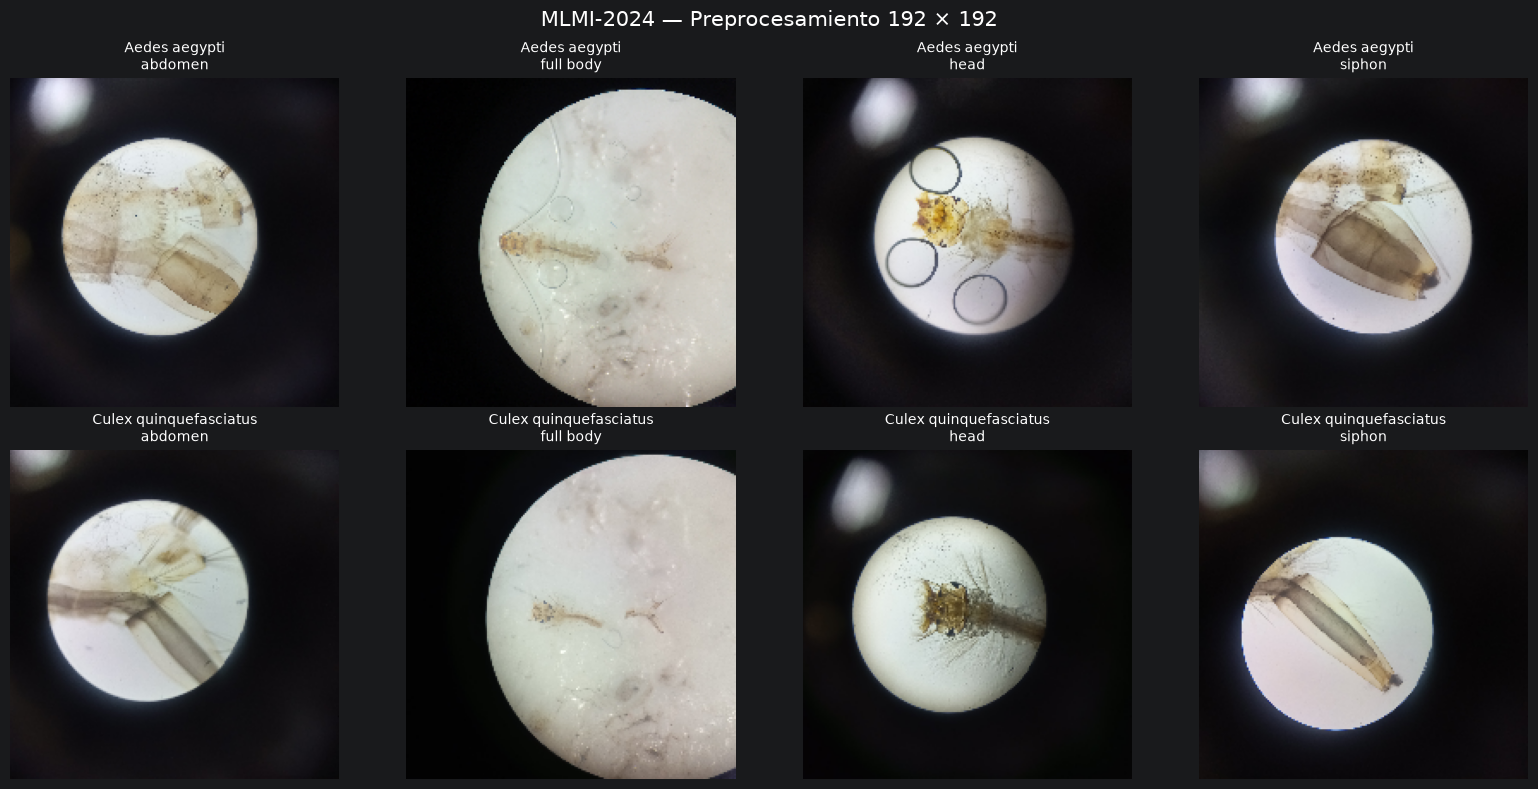

In [30]:
fig, axes = plt.subplots(
    2,
    4,
    figsize=(16, 8)
)

for fila_idx, clase in enumerate(
    CLASES_LARVAS
):

    for columna_idx, region in enumerate(
        REGIONES_LARVAS
    ):

        candidatos = df_train_mlmi[
            (
                df_train_mlmi[
                    "class_name"
                ] == clase
            )
            &
            (
                df_train_mlmi[
                    "body_region"
                ] == region
            )
        ]

        fila = candidatos.sample(
            n=1,
            random_state=SEED + fila_idx + columna_idx
        ).iloc[0]

        imagen = preparar_imagen_mlmi(
            fila["filepath"]
        )

        axes[
            fila_idx,
            columna_idx
        ].imshow(
            np.clip(
                imagen.numpy(),
                0,
                255
            ).astype(np.uint8)
        )

        axes[
            fila_idx,
            columna_idx
        ].set_title(
            f"{clase}\n{region}",
            fontsize=10
        )

        axes[
            fila_idx,
            columna_idx
        ].axis("off")


plt.suptitle(
    "MLMI-2024 — Preprocesamiento 192 × 192",
    fontsize=15
)

plt.tight_layout()
plt.show()

## Validación numérica

In [31]:
fila_prueba = (
    df_train_mlmi.iloc[0]
)

imagen_prueba = preparar_imagen_mlmi(
    fila_prueba["filepath"]
)

print(
    "Shape:",
    imagen_prueba.shape
)

print(
    "Tipo:",
    imagen_prueba.dtype
)

print(
    "Mínimo:",
    float(
        tf.reduce_min(
            imagen_prueba
        )
    )
)

print(
    "Máximo:",
    float(
        tf.reduce_max(
            imagen_prueba
        )
    )
)

assert imagen_prueba.shape == (
    192,
    192,
    3
)

print(
    "\n✅ Preprocesamiento correcto."
)

Shape: (192, 192, 3)
Tipo: <dtype: 'float32'>
Mínimo: 1.0
Máximo: 255.0

✅ Preprocesamiento correcto.


## Augmentation específico para microscopía

In [33]:
data_augmentation_mlmi = (
    keras.Sequential(
        [
            layers.RandomFlip(
                "horizontal"
            ),

            layers.RandomRotation(
                0.04
            ),

            layers.RandomZoom(
                0.08
            ),

            layers.RandomContrast(
                0.08
            )
        ],
        name="augmentation_mlmi"
    )
)

print(
    "✅ Data augmentation MLMI creado."
)

✅ Data augmentation MLMI creado.


## Comprobar augmentation

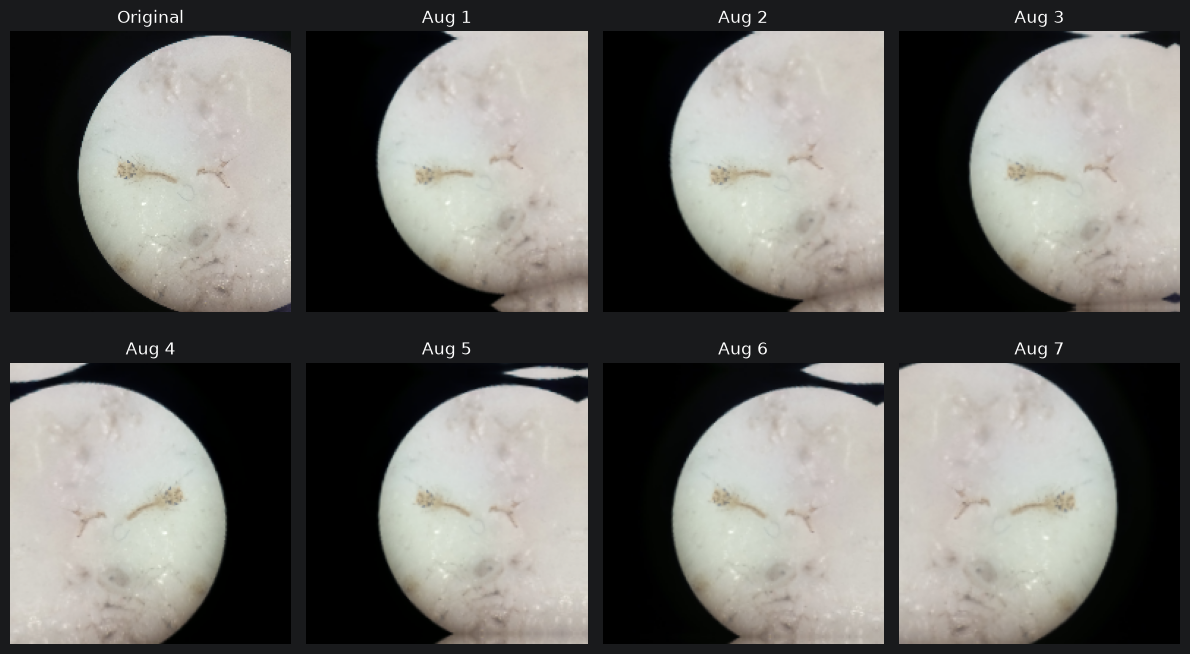

In [34]:
fig, axes = plt.subplots(
    2,
    4,
    figsize=(12, 7)
)

axes = axes.ravel()

axes[0].imshow(
    np.clip(
        imagen_prueba.numpy(),
        0,
        255
    ).astype(np.uint8)
)

axes[0].set_title(
    "Original"
)

axes[0].axis("off")


for indice in range(
    1,
    8
):

    aumentada = (
        data_augmentation_mlmi(
            tf.expand_dims(
                imagen_prueba,
                axis=0
            ),
            training=True
        )[0]
    )

    axes[indice].imshow(
        np.clip(
            aumentada.numpy(),
            0,
            255
        ).astype(np.uint8)
    )

    axes[indice].set_title(
        f"Aug {indice}"
    )

    axes[indice].axis("off")


plt.tight_layout()
plt.show()

## Generador MLMI

In [35]:
def generador_mlmi(dataframe):

    datos = (
        dataframe
        .reset_index(drop=True)
        .copy()
    )

    for _, fila in datos.iterrows():

        imagen = preparar_imagen_mlmi(
            fila["filepath"]
        )

        etiqueta = np.int32(
            fila["class_id"]
        )

        yield (
            imagen.numpy(),
            etiqueta
        )

## Crear función tf.data

In [36]:
import math


def crear_dataset_mlmi(
    dataframe,
    shuffle=False
):

    datos = (
        dataframe
        .reset_index(drop=True)
        .copy()
    )

    numero_imagenes = len(datos)

    numero_batches = math.ceil(
        numero_imagenes
        / BATCH_SIZE_MLMI
    )

    dataset = (
        tf.data.Dataset
        .from_generator(
            lambda: generador_mlmi(
                datos
            ),
            output_signature=(
                tf.TensorSpec(
                    shape=(
                        IMG_HEIGHT_MLMI,
                        IMG_WIDTH_MLMI,
                        3
                    ),
                    dtype=tf.float32
                ),

                tf.TensorSpec(
                    shape=(),
                    dtype=tf.int32
                )
            )
        )
    )

    if shuffle:

        dataset = dataset.shuffle(
            buffer_size=len(datos),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.batch(
        BATCH_SIZE_MLMI,
        drop_remainder=False
    )

    dataset = dataset.apply(
        tf.data.experimental.assert_cardinality(
            numero_batches
        )
    )

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset

## Crear datasets

In [37]:
train_ds_mlmi = crear_dataset_mlmi(
    df_train_mlmi,
    shuffle=True
)

val_ds_mlmi = crear_dataset_mlmi(
    df_val_mlmi,
    shuffle=False
)

test_ds_mlmi = crear_dataset_mlmi(
    df_test_mlmi,
    shuffle=False
)


print("=" * 60)
print("TF.DATA MLMI-2024")
print("=" * 60)

print(
    "Train batches:",
    tf.data.experimental.cardinality(
        train_ds_mlmi
    ).numpy()
)

print(
    "Validation batches:",
    tf.data.experimental.cardinality(
        val_ds_mlmi
    ).numpy()
)

print(
    "Test batches:",
    tf.data.experimental.cardinality(
        test_ds_mlmi
    ).numpy()
)

TF.DATA MLMI-2024
Train batches: 35
Validation batches: 8
Test batches: 8


## Inspeccionar un batch

In [38]:
for imagenes, etiquetas in train_ds_mlmi.take(1):

    print(
        "Shape imágenes:",
        imagenes.shape
    )

    print(
        "Shape etiquetas:",
        etiquetas.shape
    )

    print(
        "Tipo imágenes:",
        imagenes.dtype
    )

    print(
        "Tipo etiquetas:",
        etiquetas.dtype
    )

    print(
        "Píxel mínimo:",
        float(
            tf.reduce_min(
                imagenes
            )
        )
    )

    print(
        "Píxel máximo:",
        float(
            tf.reduce_max(
                imagenes
            )
        )
    )

    print(
        "Etiquetas:",
        etiquetas.numpy()
    )

Shape imágenes: (16, 192, 192, 3)
Shape etiquetas: (16,)
Tipo imágenes: <dtype: 'float32'>
Tipo etiquetas: <dtype: 'int32'>
Píxel mínimo: 0.0
Píxel máximo: 255.0
Etiquetas: [1 0 1 1 0 1 1 1 1 0 1 1 1 1 0 0]


## Construir CNN de larvas

In [39]:
cnn_larvas = keras.Sequential(
    [
        layers.Input(
            shape=(
                IMG_HEIGHT_MLMI,
                IMG_WIDTH_MLMI,
                3
            )
        ),

        # Normalización dentro del modelo.
        layers.Rescaling(
            1.0 / 255.0
        ),

        # Solo actúa durante entrenamiento.
        data_augmentation_mlmi,

        layers.Conv2D(
            32,
            kernel_size=(3, 3),
            padding="same",
            activation="relu"
        ),

        layers.MaxPooling2D(),

        layers.Conv2D(
            64,
            kernel_size=(3, 3),
            padding="same",
            activation="relu"
        ),

        layers.MaxPooling2D(),

        layers.Conv2D(
            128,
            kernel_size=(3, 3),
            padding="same",
            activation="relu"
        ),

        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            64,
            activation="relu"
        ),

        layers.Dropout(
            0.4
        ),

        # Clasificación binaria:
        # 0 = Aedes
        # 1 = Culex
        layers.Dense(
            1,
            activation="sigmoid"
        )
    ],
    name="VectorIA_CNN_Larvas"
)

cnn_larvas.summary()

Model: "VectorIA_CNN_Larvas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_mlmi (Sequential)  │ (None, 192, 192, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 192, 192, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 96, 96, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

## Compilar modelo

In [40]:
cnn_larvas.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy"
    ]
)

print(
    "✅ CNN de larvas compilada."
)

✅ CNN de larvas compilada.


## Callbacks

In [41]:
RUTA_MODELO_LARVAS = (
    MODELS
    / "cnn_larvas_mlmi.keras"
)

callbacks_larvas = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=str(
            RUTA_MODELO_LARVAS
        ),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print(
    "Modelo se guardará en:"
)

print(
    RUTA_MODELO_LARVAS
)

Modelo se guardará en:
C:\VectorAI\VectorIA\models\cnn_larvas_mlmi.keras


## Smoke test de 1 época

In [42]:
smoke_train_ds_mlmi = crear_dataset_mlmi(
    df_train_mlmi.head(64).copy(),
    shuffle=False
)

smoke_val_ds_mlmi = crear_dataset_mlmi(
    df_val_mlmi.head(32).copy(),
    shuffle=False
)

cnn_larvas_prueba = keras.models.clone_model(
    cnn_larvas
)

cnn_larvas_prueba.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_smoke_mlmi = cnn_larvas_prueba.fit(
    smoke_train_ds_mlmi,
    validation_data=smoke_val_ds_mlmi,
    epochs=1,
    verbose=1
)

print(
    "\n✅ Smoke test MLMI completado."
)

C:\VectorAI\VectorIA\.venv311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 3s/step - accuracy: 0.3750 - loss: 0.7005 - val_accuracy: 0.5625 - val_loss: 0.6926

✅ Smoke test MLMI completado.


## Liberar la prueba

In [43]:
del cnn_larvas_prueba
del history_smoke_mlmi
del smoke_train_ds_mlmi
del smoke_val_ds_mlmi

import gc

gc.collect()

print(
    "✅ Objetos temporales eliminados."
)

✅ Objetos temporales eliminados.


## Preparar entrenamiento real

In [44]:
EPOCHS_MLMI = 50

print("=" * 60)
print("CNN LARVAS MLMI-2024")
print("PREPARACIÓN FINAL")
print("=" * 60)

print(
    "Train:",
    len(df_train_mlmi)
)

print(
    "Validation:",
    len(df_val_mlmi)
)

print(
    "Test reservado:",
    len(df_test_mlmi)
)

print(
    "\nTrain batches:",
    tf.data.experimental.cardinality(
        train_ds_mlmi
    ).numpy()
)

print(
    "Validation batches:",
    tf.data.experimental.cardinality(
        val_ds_mlmi
    ).numpy()
)

print(
    "Test batches:",
    tf.data.experimental.cardinality(
        test_ds_mlmi
    ).numpy()
)

print(
    "\nÉpocas máximas:",
    EPOCHS_MLMI
)

print(
    "\nCheckpoint:"
)

print(
    RUTA_MODELO_LARVAS
)

print(
    "\n⚠️ test_ds_mlmi permanece reservado."
)

print(
    "\n✅ Preparado para entrenamiento."
)

CNN LARVAS MLMI-2024
PREPARACIÓN FINAL
Train: 559
Validation: 121
Test reservado: 120

Train batches: 35
Validation batches: 8
Test batches: 8

Épocas máximas: 50

Checkpoint:
C:\VectorAI\VectorIA\models\cnn_larvas_mlmi.keras

⚠️ test_ds_mlmi permanece reservado.

✅ Preparado para entrenamiento.


## Entrenar la CNN de larvas

In [45]:
history_larvas = cnn_larvas.fit(
    train_ds_mlmi,
    validation_data=val_ds_mlmi,
    epochs=EPOCHS_MLMI,
    callbacks=callbacks_larvas,
    verbose=1
)

Epoch 1/50


C:\VectorAI\VectorIA\.venv311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.4562 - loss: 0.6963 
Epoch 1: val_loss improved from None to 0.69312, saving model to C:\VectorAI\VectorIA\models\cnn_larvas_mlmi.keras

Epoch 1: finished saving model to C:\VectorAI\VectorIA\models\cnn_larvas_mlmi.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 89s 598ms/step - accuracy: 0.4562 - loss: 0.6963 - val_accuracy: 0.5041 - val_loss: 0.6931 - learning_rate: 0.0010
Epoch 2/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.5063 - loss: 0.6938  
Epoch 2: val_loss improved from 0.69312 to 0.69312, saving model to C:\VectorAI\VectorIA\models\cnn_larvas_mlmi.keras

Epoch 2: finished saving model to C:\VectorAI\VectorIA\models\cnn_larvas_mlmi.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 91s 504ms/step - accuracy: 0.5063 - loss: 0.6938 - val_accuracy: 0.5041 - val_loss: 0.6931 - learning_rate: 0.0010
Epoch 3/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.5295 - loss: 0.6931 
Epoch 3: val_loss improved from 0.69312 to 0.69296, saving mode

## Cargar el mejor modelo

In [46]:
assert RUTA_MODELO_LARVAS.is_file(), (
    f"No existe el modelo: {RUTA_MODELO_LARVAS}"
)

cnn_larvas_mejor = keras.models.load_model(
    RUTA_MODELO_LARVAS
)

print(
    "✅ Mejor CNN de larvas cargada."
)

print(
    "Modelo:",
    cnn_larvas_mejor.name
)

print(
    "Ruta:"
)

print(
    RUTA_MODELO_LARVAS
)

✅ Mejor CNN de larvas cargada.
Modelo: VectorIA_CNN_Larvas
Ruta:
C:\VectorAI\VectorIA\models\cnn_larvas_mlmi.keras


## Resumen del entrenamiento

In [47]:
epocas_larvas = len(
    history_larvas.history["loss"]
)

mejor_indice_larvas = int(
    np.argmin(
        history_larvas.history[
            "val_loss"
        ]
    )
)

mejor_epoca_larvas = (
    mejor_indice_larvas + 1
)

mejor_val_loss_larvas = (
    history_larvas.history[
        "val_loss"
    ][mejor_indice_larvas]
)

val_accuracy_mejor_epoca = (
    history_larvas.history[
        "val_accuracy"
    ][mejor_indice_larvas]
)

mejor_val_accuracy_larvas = max(
    history_larvas.history[
        "val_accuracy"
    ]
)

print("=" * 60)
print("RESUMEN - CNN LARVAS")
print("=" * 60)

print(
    "Épocas ejecutadas:",
    epocas_larvas
)

print(
    "Época con menor val_loss:",
    mejor_epoca_larvas
)

print(
    "Mejor val_loss:",
    round(
        mejor_val_loss_larvas,
        4
    )
)

print(
    "val_accuracy en esa época:",
    round(
        val_accuracy_mejor_epoca,
        4
    )
)

print(
    "Mayor val_accuracy observada:",
    round(
        mejor_val_accuracy_larvas,
        4
    )
)

RESUMEN - CNN LARVAS
Épocas ejecutadas: 47
Época con menor val_loss: 39
Mejor val_loss: 0.2435
val_accuracy en esa época: 0.9091
Mayor val_accuracy observada: 0.9091


## Predicciones sobre validation

In [48]:
prob_val_larvas = (
    cnn_larvas_mejor.predict(
        val_ds_mlmi,
        verbose=1
    )
    .reshape(-1)
)

pred_val_larvas = (
    prob_val_larvas >= 0.5
).astype(np.int32)

y_val_larvas = (
    df_val_mlmi[
        "class_id"
    ]
    .to_numpy(
        dtype=np.int32
    )
)


print(
    "Etiquetas reales:",
    len(y_val_larvas)
)

print(
    "Predicciones:",
    len(pred_val_larvas)
)

print(
    "Probabilidades:",
    prob_val_larvas.shape
)

print(
    "\nRango sigmoid:",
    f"{prob_val_larvas.min():.4f}",
    "-",
    f"{prob_val_larvas.max():.4f}"
)


assert (
    len(y_val_larvas)
    == len(pred_val_larvas)
)

print(
    "\n✅ Predicciones de validation generadas."
)

8/8 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step
Etiquetas reales: 121
Predicciones: 121
Probabilidades: (121,)

Rango sigmoid: 0.0008 - 0.9774

✅ Predicciones de validation generadas.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("✅ Métricas de scikit-learn disponibles.")

## F1 macro en validation

In [52]:
accuracy_val_larvas = accuracy_score(
    y_val_larvas,
    pred_val_larvas
)

precision_val_larvas = precision_score(
    y_val_larvas,
    pred_val_larvas,
    labels=[0, 1],
    average="macro",
    zero_division=0
)

recall_val_larvas = recall_score(
    y_val_larvas,
    pred_val_larvas,
    labels=[0, 1],
    average="macro",
    zero_division=0
)

f1_val_larvas = f1_score(
    y_val_larvas,
    pred_val_larvas,
    labels=[0, 1],
    average="macro",
    zero_division=0
)


print("=" * 60)
print("CNN LARVAS - VALIDACIÓN")
print("=" * 60)

print(
    f"Accuracy:        "
    f"{accuracy_val_larvas:.4f}"
)

print(
    f"Precision macro: "
    f"{precision_val_larvas:.4f}"
)

print(
    f"Recall macro:    "
    f"{recall_val_larvas:.4f}"
)

print(
    f"F1 macro:        "
    f"{f1_val_larvas:.4f}"
)

CNN LARVAS - VALIDACIÓN
Accuracy:        0.9091
Precision macro: 0.9092
Recall macro:    0.9092
F1 macro:        0.9091


## Reporte por especie

In [53]:
reporte_larvas = classification_report(
    y_val_larvas,
    pred_val_larvas,
    labels=[0, 1],
    target_names=CLASES_LARVAS,
    zero_division=0,
    output_dict=True
)

df_reporte_larvas = (
    pd.DataFrame(
        reporte_larvas
    )
    .transpose()
)

display(
    df_reporte_larvas.round(4)
)

,precision,recall,f1-score,support
Aedes aegypti,0.9016,0.9167,0.9091,60.0000
Culex quinquefasciatus,0.9167,0.9016,0.9091,61.0000
accuracy,0.9091,0.9091,0.9091,0.9091
macro avg,0.9092,0.9092,0.9091,121.0000
weighted avg,0.9092,0.9091,0.9091,121.0000


## Matriz

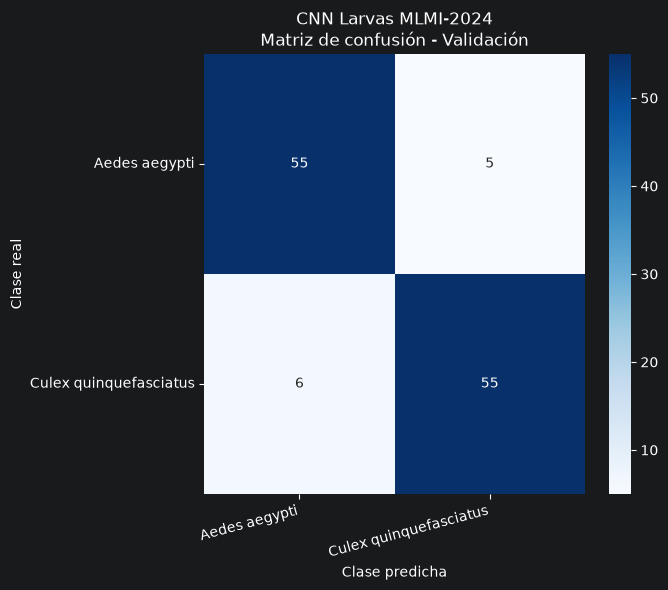

In [54]:
cm_val_larvas = confusion_matrix(
    y_val_larvas,
    pred_val_larvas,
    labels=[0, 1]
)

plt.figure(
    figsize=(7, 6)
)

sns.heatmap(
    cm_val_larvas,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASES_LARVAS,
    yticklabels=CLASES_LARVAS
)

plt.title(
    "CNN Larvas MLMI-2024\n"
    "Matriz de confusión - Validación"
)

plt.xlabel(
    "Clase predicha"
)

plt.ylabel(
    "Clase real"
)

plt.xticks(
    rotation=15,
    ha="right"
)

plt.yticks(
    rotation=0
)

plt.tight_layout()
plt.show()

## Rendimiento según región anatómica

In [55]:
resultados_val_larvas = (
    df_val_mlmi[
        [
            "class_name",
            "class_id",
            "body_region",
            "filepath"
        ]
    ]
    .copy()
)

resultados_val_larvas[
    "pred_class_id"
] = pred_val_larvas

resultados_val_larvas[
    "pred_class_name"
] = (
    resultados_val_larvas[
        "pred_class_id"
    ]
    .map(
        ID_TO_CLASS_LARVAS
    )
)

resultados_val_larvas[
    "score_culex"
] = prob_val_larvas

resultados_val_larvas[
    "correcta"
] = (
    resultados_val_larvas[
        "class_id"
    ]
    ==
    resultados_val_larvas[
        "pred_class_id"
    ]
)


resumen_region = (
    resultados_val_larvas
    .groupby(
        "body_region"
    )
    .agg(
        imagenes=(
            "correcta",
            "size"
        ),
        accuracy=(
            "correcta",
            "mean"
        )
    )
)

display(
    resumen_region.round(4)
)

,imagenes,accuracy
body_region,,
abdomen,30,0.8667
full body,30,0.9000
head,31,0.9032
siphon,30,0.9667


## F1 macro por región

In [56]:
metricas_region = []

for region, datos in (
    resultados_val_larvas
    .groupby(
        "body_region"
    )
):

    f1_region = f1_score(
        datos["class_id"],
        datos["pred_class_id"],
        labels=[0, 1],
        average="macro",
        zero_division=0
    )

    metricas_region.append({
        "Región": region,
        "Imágenes": len(datos),
        "F1 macro": f1_region
    })


df_metricas_region = (
    pd.DataFrame(
        metricas_region
    )
    .sort_values(
        "F1 macro",
        ascending=False
    )
)

display(
    df_metricas_region.round(4)
)

,Región,Imágenes,F1 macro
3,siphon,30,0.9666
2,head,31,0.9032
1,full body,30,0.8990
0,abdomen,30,0.8661


## Verificacion final Splits

In [57]:
print("=" * 60)
print("SPLITS FINALES MLMI-2024")
print("=" * 60)

print("Train:", len(df_train_mlmi))
print("Validation:", len(df_val_mlmi))
print("Test:", len(df_test_mlmi))

print(
    "Total:",
    len(df_train_mlmi)
    + len(df_val_mlmi)
    + len(df_test_mlmi)
)

assert (
    len(df_train_mlmi)
    + len(df_val_mlmi)
    + len(df_test_mlmi)
    == 800
)

print("\nDistribución TEST:")

display(
    pd.crosstab(
        df_test_mlmi["class_name"],
        df_test_mlmi["body_region"]
    ).reindex(
        index=CLASES_LARVAS,
        columns=REGIONES_LARVAS,
        fill_value=0
    )
)

print(
    "\n✅ Splits verificados. "
    "El modelo queda congelado antes de TEST."
)

SPLITS FINALES MLMI-2024
Train: 559
Validation: 121
Test: 120
Total: 800

Distribución TEST:


body_region,abdomen,full body,head,siphon
class_name,,,,
Aedes aegypti,15,15,15,15
Culex quinquefasciatus,15,15,15,15



✅ Splits verificados. El modelo queda congelado antes de TEST.


## Predicción final sobre TEST

In [58]:
prob_test_larvas = (
    cnn_larvas_mejor.predict(
        test_ds_mlmi,
        verbose=1
    )
    .reshape(-1)
)

# Threshold definido previamente.
pred_test_larvas = (
    prob_test_larvas >= 0.5
).astype(np.int32)

y_test_larvas = (
    df_test_mlmi["class_id"]
    .to_numpy(dtype=np.int32)
)

print(
    "Etiquetas reales:",
    len(y_test_larvas)
)

print(
    "Predicciones:",
    len(pred_test_larvas)
)

assert (
    len(y_test_larvas)
    == len(pred_test_larvas)
)

print(
    "\n✅ Predicciones finales generadas."
)

8/8 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step
Etiquetas reales: 120
Predicciones: 120

✅ Predicciones finales generadas.


## Métricas finales del bonus ( larvas )

In [59]:
accuracy_test_larvas = accuracy_score(
    y_test_larvas,
    pred_test_larvas
)

precision_test_larvas = precision_score(
    y_test_larvas,
    pred_test_larvas,
    labels=[0, 1],
    average="macro",
    zero_division=0
)

recall_test_larvas = recall_score(
    y_test_larvas,
    pred_test_larvas,
    labels=[0, 1],
    average="macro",
    zero_division=0
)

f1_test_larvas = f1_score(
    y_test_larvas,
    pred_test_larvas,
    labels=[0, 1],
    average="macro",
    zero_division=0
)

print("=" * 60)
print("CNN LARVAS MLMI-2024 - TEST FINAL")
print("=" * 60)

print(
    f"Accuracy:        "
    f"{accuracy_test_larvas:.4f}"
)

print(
    f"Precision macro: "
    f"{precision_test_larvas:.4f}"
)

print(
    f"Recall macro:    "
    f"{recall_test_larvas:.4f}"
)

print(
    f"F1 macro:        "
    f"{f1_test_larvas:.4f}"
)

CNN LARVAS MLMI-2024 - TEST FINAL
Accuracy:        0.9167
Precision macro: 0.9171
Recall macro:    0.9167
F1 macro:        0.9166


## Resultados finales por especie

In [60]:
reporte_test_larvas = classification_report(
    y_test_larvas,
    pred_test_larvas,
    labels=[0, 1],
    target_names=CLASES_LARVAS,
    zero_division=0,
    output_dict=True
)

df_reporte_test_larvas = (
    pd.DataFrame(
        reporte_test_larvas
    )
    .transpose()
)

display(
    df_reporte_test_larvas.round(4)
)

,precision,recall,f1-score,support
Aedes aegypti,0.9310,0.9000,0.9153,60.0000
Culex quinquefasciatus,0.9032,0.9333,0.9180,60.0000
accuracy,0.9167,0.9167,0.9167,0.9167
macro avg,0.9171,0.9167,0.9166,120.0000
weighted avg,0.9171,0.9167,0.9166,120.0000


## Matriz de confusión final

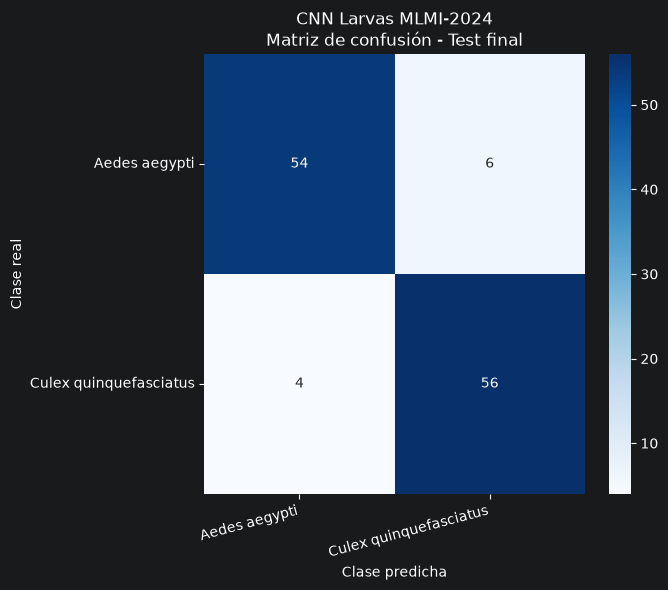

In [61]:
cm_test_larvas = confusion_matrix(
    y_test_larvas,
    pred_test_larvas,
    labels=[0, 1]
)

plt.figure(
    figsize=(7, 6)
)

sns.heatmap(
    cm_test_larvas,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASES_LARVAS,
    yticklabels=CLASES_LARVAS
)

plt.title(
    "CNN Larvas MLMI-2024\n"
    "Matriz de confusión - Test final"
)

plt.xlabel("Clase predicha")
plt.ylabel("Clase real")

plt.xticks(
    rotation=15,
    ha="right"
)

plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

## F1 final por región anatómica

In [62]:
resultados_test_larvas = (
    df_test_mlmi[
        [
            "class_name",
            "class_id",
            "body_region",
            "filepath"
        ]
    ]
    .copy()
)

resultados_test_larvas[
    "pred_class_id"
] = pred_test_larvas

resultados_test_larvas[
    "score_culex"
] = prob_test_larvas

resultados_test_larvas[
    "correcta"
] = (
    resultados_test_larvas["class_id"]
    ==
    resultados_test_larvas["pred_class_id"]
)


metricas_test_region = []

for region, datos in (
    resultados_test_larvas
    .groupby("body_region")
):

    f1_region = f1_score(
        datos["class_id"],
        datos["pred_class_id"],
        labels=[0, 1],
        average="macro",
        zero_division=0
    )

    metricas_test_region.append({
        "Región": region,
        "Imágenes": len(datos),
        "Accuracy": datos["correcta"].mean(),
        "F1 macro": f1_region
    })


df_test_region = pd.DataFrame(
    metricas_test_region
).sort_values(
    "F1 macro",
    ascending=False
)

display(
    df_test_region.round(4)
)

,Región,Imágenes,Accuracy,F1 macro
3,siphon,30,1.0000,1.0000
1,full body,30,0.9333,0.9333
0,abdomen,30,0.8667,0.8661
2,head,30,0.8667,0.8643


## Guardar métricas finales

In [63]:
metricas_finales_larvas = pd.DataFrame([
    {
        "Modelo": "CNN Larvas MLMI-2024",
        "Accuracy_validation": accuracy_val_larvas,
        "F1_macro_validation": f1_val_larvas,
        "Accuracy_test": accuracy_test_larvas,
        "Precision_macro_test": precision_test_larvas,
        "Recall_macro_test": recall_test_larvas,
        "F1_macro_test": f1_test_larvas,
        "F1_Aedes_aegypti": (
            reporte_test_larvas[
                "Aedes aegypti"
            ]["f1-score"]
        ),
        "F1_Culex_quinquefasciatus": (
            reporte_test_larvas[
                "Culex quinquefasciatus"
            ]["f1-score"]
        )
    }
])

RUTA_METRICAS_LARVAS = (
    PROCESSED_MLMI
    / "mlmi_final_test_metrics.csv"
)

metricas_finales_larvas.to_csv(
    RUTA_METRICAS_LARVAS,
    index=False,
    encoding="utf-8-sig"
)

display(
    metricas_finales_larvas.round(4)
)

print("\nMétricas guardadas en:")
print(RUTA_METRICAS_LARVAS)

assert RUTA_METRICAS_LARVAS.is_file()

print(
    "\n✅ Métricas finales guardadas."
)

,Modelo,Accuracy_validation,F1_macro_validation,Accuracy_test,Precision_macro_test,Recall_macro_test,F1_macro_test,F1_Aedes_aegypti,F1_Culex_quinquefasciatus
0,CNN Larvas MLMI-2024,0.9091,0.9091,0.9167,0.9171,0.9167,0.9166,0.9153,0.918



Métricas guardadas en:
C:\VectorAI\VectorIA\data\processed\mlmi\mlmi_final_test_metrics.csv

✅ Métricas finales guardadas.


## Guardar métricas por región

In [64]:
RUTA_METRICAS_REGION = (
    PROCESSED_MLMI
    / "mlmi_test_metrics_by_region.csv"
)

df_test_region.to_csv(
    RUTA_METRICAS_REGION,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Métricas por región guardadas:"
)

print(
    RUTA_METRICAS_REGION
)

display(
    df_test_region.round(4)
)

Métricas por región guardadas:
C:\VectorAI\VectorIA\data\processed\mlmi\mlmi_test_metrics_by_region.csv


,Región,Imágenes,Accuracy,F1 macro
3,siphon,30,1.0000,1.0000
1,full body,30,0.9333,0.9333
0,abdomen,30,0.8667,0.8661
2,head,30,0.8667,0.8643


## Crear configuración del modelo ( json )

In [65]:
import json

config_larvas = {
    "model_name": "VectorIA CNN Larvas MLMI-2024",

    "model_file": "cnn_larvas_mlmi.keras",

    "model_type": "Binary CNN",

    "experimental_bonus": True,

    "input_width": 192,
    "input_height": 192,
    "input_channels": 3,

    "color_mode": "RGB",

    "resize_method": "resize_with_pad",

    "input_range": [
        0,
        255
    ],

    "normalization_inside_model": True,

    "classes": [
        "Aedes aegypti",
        "Culex quinquefasciatus"
    ],

    "class_ids": {
        "Aedes aegypti": 0,
        "Culex quinquefasciatus": 1
    },

    "output_activation": "sigmoid",

    "threshold": 0.5,

    "validation_metrics": {
        "accuracy": float(
            accuracy_val_larvas
        ),
        "f1_macro": float(
            f1_val_larvas
        )
    },

    "test_metrics": {
        "accuracy": float(
            accuracy_test_larvas
        ),
        "precision_macro": float(
            precision_test_larvas
        ),
        "recall_macro": float(
            recall_test_larvas
        ),
        "f1_macro": float(
            f1_test_larvas
        )
    },

    "body_regions": [
        "abdomen",
        "full body",
        "head",
        "siphon"
    ],

    "notes": (
        "Modelo experimental bonus entrenado "
        "con imágenes microscópicas MLMI-2024. "
        "No sustituye el clasificador principal "
        "de mosquitos adultos de VectorIA."
    )
}

RUTA_CONFIG_LARVAS = (
    MODELS
    / "cnn_larvas_mlmi_config.json"
)

with RUTA_CONFIG_LARVAS.open(
    "w",
    encoding="utf-8"
) as archivo:

    json.dump(
        config_larvas,
        archivo,
        indent=2,
        ensure_ascii=False
    )

print(
    "Configuración guardada:"
)

print(
    RUTA_CONFIG_LARVAS
)

assert RUTA_CONFIG_LARVAS.is_file()

print(
    "\n✅ Configuración guardada."
)

Configuración guardada:
C:\VectorAI\VectorIA\models\cnn_larvas_mlmi_config.json

✅ Configuración guardada.


## entregables

In [66]:
entregables_larvas = [
    RUTA_MODELO_LARVAS,
    RUTA_CONFIG_LARVAS,
    RUTA_SPLITS_MLMI,
    RUTA_METRICAS_LARVAS,
    RUTA_METRICAS_REGION
]

print("=" * 60)
print("ENTREGABLES BONUS MLMI-2024")
print("=" * 60)

for archivo in entregables_larvas:

    existe = archivo.is_file()

    simbolo = (
        "✅"
        if existe
        else "❌"
    )

    print(
        f"{simbolo} {archivo}"
    )

assert all(
    archivo.is_file()
    for archivo in entregables_larvas
)

print(
    "\n✅ Bonus MLMI-2024 "
    "guardado correctamente."
)

ENTREGABLES BONUS MLMI-2024
✅ C:\VectorAI\VectorIA\models\cnn_larvas_mlmi.keras
✅ C:\VectorAI\VectorIA\models\cnn_larvas_mlmi_config.json
✅ C:\VectorAI\VectorIA\data\processed\mlmi\mlmi_splits.csv
✅ C:\VectorAI\VectorIA\data\processed\mlmi\mlmi_final_test_metrics.csv
✅ C:\VectorAI\VectorIA\data\processed\mlmi\mlmi_test_metrics_by_region.csv

✅ Bonus MLMI-2024 guardado correctamente.
